# CDS energy datasets — what exists for Sweden?

Goal: catalogue **what data exists** (variables, temporal resolution, spatial
aggregation, time coverage) for Sweden in three Copernicus C3S Energy datasets:

| dataset id | catalogue page |
|---|---|
| `sis-energy-global-reanalysis`  | https://cds.climate.copernicus.eu/datasets/sis-energy-global-reanalysis |
| `sis-energy-derived-projections`| https://cds.climate.copernicus.eu/datasets/sis-energy-derived-projections |
| `sis-energy-pecd`               | https://cds.climate.copernicus.eu/datasets/sis-energy-pecd |

Strategy: read the **catalogue metadata / form / constraints** first (cheap, no data
transfer) to enumerate the option space, then pull only a couple of tiny
Sweden-only samples at the finest temporal resolution to confirm the actual shape.

## Which client

Two libraries, each doing the thing it is best at:

| layer | role | call |
|---|---|---|
| **`ecmwf-datastores-client`** | catalogue, form, constraints, cost, size-before-download, licences | `Client()`, `col.form`, `col.constraints`, `col.apply_constraints(...)`, `col.estimate_costs(...)` |
| **`earthkit`** | retrieve + cache + **decode** in one call | `ekd.from_source("cds", ds, req)` then `.to_pandas()` / `.to_fieldlist()` |

`ecmwf-datastores-client` is the designated successor to `cdsapi` - in fact
`cdsapi >= 0.7.2` is now a thin shim **over** it (`pip show ecmwf-datastores-client`
reports `Required-by: cdsapi`). Going through `cdsapi` only adds a legacy
compatibility layer, so this notebook uses the datastores client directly.

Nothing here needs raw `requests`: the datastores client wraps every catalogue and
retrieve endpoint, including the two that `cdsapi` never exposed - `apply_constraints`
and `estimate_costs`.

**Auth note:** a bare `Client()` looks for `~/.ecmwfdatastoresrc` and does *not* read
`CDSAPI_URL` / `CDSAPI_KEY`. We pass them explicitly from `.env`.

## 0. Setup


In [1]:
import json
import os
import zipfile
from pathlib import Path

import earthkit.data as ekd
import pandas as pd
from dotenv import load_dotenv
from ecmwf.datastores import Client

load_dotenv(Path.cwd().parent / ".env")

CDS_URL = os.environ["CDSAPI_URL"].rstrip("/")
CDS_KEY = os.environ["CDSAPI_KEY"]

DATASETS = [
    "sis-energy-global-reanalysis",
    "sis-energy-derived-projections",
    "sis-energy-pecd",
]

# A bare Client() wants ~/.ecmwfdatastoresrc; pass the .env credentials instead.
cds = Client(url=CDS_URL, key=CDS_KEY)
COLLECTIONS = {ds: cds.get_collection(ds) for ds in DATASETS}

ekd.settings.set("cache-policy", "user")
print("CDS:", CDS_URL)
print("earthkit cache:", ekd.cache.directory(), "| policy:", ekd.settings.get("cache-policy"))
print("collections loaded:", list(COLLECTIONS))

CDS: https://cds.climate.copernicus.eu/api
earthkit cache: /tmp/earthkit-data-kaarel | policy: user
collections loaded: ['sis-energy-global-reanalysis', 'sis-energy-derived-projections', 'sis-energy-pecd']


## 1. Catalogue metadata

`/api/catalogue/v1/collections/{id}` gives title, abstract, temporal/spatial extent
and keywords without transferring any data.


In [2]:
# Collection objects expose the catalogue metadata as typed attributes -
# no hand-built URLs, no raw JSON digging.
for ds, col in COLLECTIONS.items():
    print("=" * 78)
    print(ds)
    print("=" * 78)
    print("title   :", col.title)
    print("temporal:", col.begin_datetime, "->", col.end_datetime)
    print("bbox    :", col.bbox)
    print("updated :", col.updated_at, "| published:", col.published_at)
    print("url     :", col.url)
    print("description:", str(col.description)[:600])
    print()

sis-energy-global-reanalysis
title   : Global climate and energy indicators from 1950 to present derived from reanalysis
temporal: 1950-01-01 00:00:00+00:00 -> 2026-08-01 00:00:00+00:00
bbox    : (0.0, -90.0, 360.0, 90.0)
updated : 2026-09-07 00:00:00+00:00 | published: 2026-06-02 00:00:00+00:00
url     : https://cds.climate.copernicus.eu/api/catalogue/v1/collections/sis-energy-global-reanalysis
description: This dataset provides global climate and energy indicators from 1950 to the present at hourly and coarser temporal resolutions, offering a long-term, harmonised data foundation for energy-sector applications. It enables users to analyse energy indicators for the past climate, supporting energy planning, system design, risk assessments, climate impact modelling and model benchmarking. Based on ECMWF reanalysis v5 (ERA5), it includes key climate variables, such as temperature, precipitation, surface solar radiation and wind speed, that have been pre-processed to enhance consistency a

### 1b. Documentation links (region-code definitions live here)


In [3]:
# Anything the typed attributes do not cover is still on the raw STAC document.
for ds, col in COLLECTIONS.items():
    doc = col.json
    print("=" * 78)
    print(ds, "| licence:", doc.get("license"), "| DOI:", doc.get("sci:doi"))
    print("   update frequency:", doc.get("cads:update_frequency"))
    print("   keywords:", doc.get("keywords"))

sis-energy-global-reanalysis | licence: CC-BY-4.0 | DOI: 10.24381/3bb607bd
   update frequency: Monthly
   keywords: ['Product type: Reanalysis', 'Temporal coverage: Past', 'Spatial coverage: Global', 'Variable domain: Atmosphere (surface)', 'Provider: Copernicus C3S', 'Sector: Energy']
sis-energy-derived-projections | licence: CC-BY-4.0 | DOI: 10.24381/cds.f6951a62
   update frequency: Not planned
   keywords: ['Spatial coverage: Europe', 'Temporal coverage: Present', 'Variable domain: Atmosphere (surface)', 'Product type: Climate projections', 'Temporal coverage: Future', 'Sector: Energy']
sis-energy-pecd | licence: other | DOI: 10.24381/cds.f323c5ec
   update frequency: Monthly
   keywords: ['Product type: Reanalysis', 'Temporal coverage: Past', 'Spatial coverage: Europe', 'Variable domain: Atmosphere (surface)', 'Provider: Copernicus C3S', 'Product type: Climate projections', 'Temporal coverage: Future', 'Product type: Climate indices', 'Sector: Energy']


## 2. Request form — the full option space

`form.json` lists every widget and its allowed values: this _is_ the answer to
"what data exactly is available".


In [4]:
def form_of(ds):
    # col.form is the parsed request form - the same JSON the web portal renders.
    return COLLECTIONS[ds].form


def _values(d):
    """Pull the option list out of a widget/group detail blob."""
    v = d.get("values")
    if v:
        return list(v)
    lab = d.get("labels")
    if isinstance(lab, (dict, list)):
        return list(lab)
    return []


def _walk_groups(d, indent, out):
    """Groups nest as group -> details -> groups, so descend through both."""
    for g in (d.get("groups") or []) + (d.get("details", {}) or {}).get("groups", []):
        vals = _values(g)
        out.append(f"{indent}group {g.get('label') or g.get('name')!r} (n={len(vals)})")
        if vals:
            out.append(f"{indent}  {json.dumps(vals, ensure_ascii=False)}")
        _walk_groups(g, indent + "  ", out)


SKIP = {"FreeEditionWidget", "ExclusiveFrameWidget", "LicenceWidget", "GeographicExtentWidget"}


def summarise_form(ds, max_values=400):
    print("#" * 78)
    print("#", ds)
    print("#" * 78)
    for w in form_of(ds):
        typ = w.get("type", "")
        if typ in SKIP:
            continue
        details = w.get("details", {}) or {}
        vals = _values(details)
        print(f"\n[{w.get('name')}]  ({typ})  label={w.get('label')!r}  n={len(vals)}")
        if vals:
            print("   ", json.dumps(vals[:max_values], ensure_ascii=False))
            if len(vals) > max_values:
                print(f"    ... +{len(vals) - max_values} more")
        lines = []
        _walk_groups(details, "    ", lines)
        print("\n".join(lines))


summarise_form(DATASETS[0])

##############################################################################
# sis-energy-global-reanalysis
##############################################################################



[spatial_coverage]  (StringChoiceWidget)  label='Spatial coverage'  n=2
    ["europe", "global"]


[variable]  (StringListArrayWidget)  label='Variable'  n=0
    group 'Climate' (n=6)
      ["2m_temperature", "10m_wind_speed", "100m_wind_speed", "100m_wind_speed_extrapolated", "surface_solar_radiation_downwards", "total_precipitation"]
    group 'Energy' (n=0)
      group 'Hydro energy' (n=4)
        ["hydropower_reservoirs_generation", "hydropower_reservoirs_inflow", "hydropower_run_of_river_generation", "installed_capacity_weighted_total_precipitation"]
      group 'Solar energy' (n=1)
        ["solar_photovoltaic_generation_capacity_factor"]
      group 'Wind energy' (n=2)
        ["wind_power_offshore_capacity_factor", "wind_power_onshore_capacity_factor"]
      group 'Energy demand' (n=4)
        ["cooling_degree_days", "heating_degree_days", "energy_degree_days", "electricity_demand"]
    group 'Weights and masks' (n=18)
      ["country_aggregation_mask", "country_aggregation_ma

In [5]:
from collections import defaultdict


def constraints_of(ds):
    # col.constraints is the same list of conjunction blocks the portal uses.
    return COLLECTIONS[ds].constraints


def summarise_constraints(ds, key=None):
    """Show which values of each field co-occur, i.e. the *valid* combinations."""
    cons = constraints_of(ds)
    print(f"{ds}: {len(cons)} constraint block(s)")
    fields = sorted({k for c in cons for k in c})
    print("fields:", fields)
    if key is None:
        return cons
    acc = defaultdict(lambda: defaultdict(set))
    for c in cons:
        for kv in c.get(key, []):
            for f in fields:
                if f != key:
                    acc[kv][f] |= set(c.get(f, []))
    for kv in sorted(acc):
        print(f"\n--- {key} = {kv}")
        for f, s in acc[kv].items():
            s = sorted(s)
            print(f"    {f} (n={len(s)}): {s[:60]}{' ...' if len(s) > 60 else ''}")
    return cons

In [6]:
summarise_form(DATASETS[1])

##############################################################################
# sis-energy-derived-projections
##############################################################################

[variable]  (StringListArrayWidget)  label='Variable'  n=0
    group 'Meterology' (n=5)
      ["wind_speed_at_100m", "wind_speed_at_10m", "surface_downwelling_shortwave_radiation", "2m_air_temperature", "total_precipitation"]
    group 'Energy' (n=6)
      ["electricity_demand", "hydro_power_generation_reservoirs", "hydro_power_generation_rivers", "solar_photovoltaic_power_generation", "wind_power_generation_offshore", "wind_power_generation_onshore"]

[spatial_aggregation]  (StringChoiceWidget)  label='Spatial aggregation'  n=5
    ["country_level", "sub_country_level", "maritime_country_level", "maritime_sub_country_level", "original_grid"]


[energy_product_type]  (StringListWidget)  label='Energy product type'  n=3
    ["capacity_factor_ratio", "energy", "power"]


[temporal_aggregation]  (Str

In [7]:
summarise_form(DATASETS[2])

##############################################################################
# sis-energy-pecd
##############################################################################

[pecd_version]  (StringChoiceWidget)  label='PECD version'  n=2
    ["deprecated", "pecd4_2"]


[temporal_period]  (StringListWidget)  label='Temporal period'  n=2
    ["historical", "future_projections"]


[origin]  (StringListArrayWidget)  label='Origin'  n=0
    group 'Reanalysis' (n=1)
      ["era5_reanalysis"]
    group 'Climate models' (n=6)
      ["cmcc_cm2_sr5", "ec_earth3", "mpi_esm1_2_hr", "awi_cm_1_1_mr", "bcc_csm2_mr", "mri_esm2_0"]

[emission_scenario]  (StringListWidget)  label='Emission scenario'  n=4
    ["ssp1_2_6", "ssp2_4_5", "ssp3_7_0", "ssp5_8_5"]


[variable]  (StringListArrayWidget)  label='Variable'  n=0
    group 'Climate' (n=6)
      ["100m_wind_speed", "10m_wind_speed", "2m_temperature", "population_weighted_temperature", "surface_solar_radiation_downwards", "total_precipitation"]
    

### 2b. Raw widget JSON

The `Energy` variable group renders empty for `sis-energy-global-reanalysis` and
`sis-energy-pecd`. Check the raw JSON to see whether those variables are genuinely
absent or just keyed differently.


In [8]:
for ds in ("sis-energy-global-reanalysis", "sis-energy-pecd"):
    for w in form_of(ds):
        if w.get("name") in ("variable", "area_group"):
            print("=" * 78)
            print(ds, "->", w["name"])
            print(json.dumps(w, indent=1, ensure_ascii=False)[:4000])
            print()

sis-energy-global-reanalysis -> variable
{
 "name": "variable",
 "label": "Variable",
 "help": "The weights and masks are ancillary data. Please consult Table 5.2 & 5.3 in the Product User Guide in the Documentation section for more information on these variables.",
 "required": true,
 "css": "todo",
 "type": "StringListArrayWidget",
 "details": {
  "groups": [
   {
    "label": "Climate",
    "open": false,
    "columns": 3,
    "values": [
     "2m_temperature",
     "10m_wind_speed",
     "100m_wind_speed",
     "100m_wind_speed_extrapolated",
     "surface_solar_radiation_downwards",
     "total_precipitation"
    ],
    "labels": {
     "2m_temperature": "2m temperature",
     "10m_wind_speed": "10m wind speed",
     "100m_wind_speed": "100m wind speed",
     "100m_wind_speed_extrapolated": "100m wind speed extrapolated",
     "surface_solar_radiation_downwards": "Surface solar radiation downwards",
     "total_precipitation": "Total precipitation"
    }
   },
   {
    "label": "E

## 3. Constraints — which combinations are actually valid

`constraints.json` is the authoritative list of selectable combinations.


In [ ]:
cons_gr = summarise_constraints(
    "sis-energy-global-reanalysis", key="temporal_resolution"
)

sis-energy-global-reanalysis: 49 constraint block(s)
fields: ['file_format', 'month', 'spatial_coverage', 'spatial_resolution', 'technological_specification', 'temporal_resolution', 'variable', 'version', 'year']

--- temporal_resolution = 1_day
    file_format (n=1): ['csv']
    month (n=12): ['01', '02', '03', '04', '05', '06', '07', '08', '09', '10', '11', '12']
    spatial_coverage (n=2): ['europe', 'global']
    spatial_resolution (n=2): ['admin_0', 'admin_1']
    technological_specification (n=5): ['ic2_5hh100', 'ic2_5hh100e', 'ic3_3hh84', 'ic6hh135', 'ic6hh135e']
    variable (n=9): ['100m_wind_speed', '100m_wind_speed_extrapolated', '10m_wind_speed', '2m_temperature', 'electricity_demand', 'solar_photovoltaic_generation_capacity_factor', 'surface_solar_radiation_downwards', 'total_precipitation', 'wind_power_onshore_capacity_factor']
    version (n=1): ['1_00']
    year (n=77): ['1950', '1951', '1952', '1953', '1954', '1955', '1956', '1957', '1958', '1959', '1960', '1961', '196

In [10]:
cons_dp = summarise_constraints(
    "sis-energy-derived-projections", key="temporal_aggregation"
)

sis-energy-derived-projections: 125 constraint block(s)
fields: ['energy_product_type', 'ensemble_member', 'experiment', 'gcm', 'rcm', 'spatial_aggregation', 'temporal_aggregation', 'variable']

--- temporal_aggregation = 3_hourly
    energy_product_type (n=1): ['capacity_factor_ratio']
    ensemble_member (n=3): ['r12i1p1', 'r1i1p1', 'r3i1p1']
    experiment (n=3): ['rcp_2_6', 'rcp_4_5', 'rcp_8_5']
    gcm (n=6): ['cnrm_cm5', 'ec_earth', 'hadgem2_es', 'ipsl_cm5a_mr', 'mpi_esm_lr', 'noresm1_m']
    rcm (n=7): ['aladin63', 'cclm4_8_17', 'hirham5', 'racmo22e', 'rca4', 'regcm4', 'wrf381p']
    spatial_aggregation (n=4): ['country_level', 'maritime_country_level', 'maritime_sub_country_level', 'original_grid']
    variable (n=7): ['2m_air_temperature', 'solar_photovoltaic_power_generation', 'surface_downwelling_shortwave_radiation', 'wind_power_generation_offshore', 'wind_power_generation_onshore', 'wind_speed_at_100m', 'wind_speed_at_10m']

--- temporal_aggregation = annual
    energy_pro

In [11]:
cons_pecd = summarise_constraints("sis-energy-pecd", key="temporal_period")

sis-energy-pecd: 75 constraint block(s)
fields: ['emission_scenario', 'energy_scenario', 'file_version', 'month', 'origin', 'pecd_version', 'spatial_resolution', 'technology', 'temporal_period', 'variable', 'year']

--- temporal_period = future_projections
    emission_scenario (n=4): ['ssp1_2_6', 'ssp2_4_5', 'ssp3_7_0', 'ssp5_8_5']
    energy_scenario (n=2): ['resource_grade_a', 'resource_grade_b']
    file_version (n=2): ['fv1', 'fv2']
    month (n=12): ['01', '02', '03', '04', '05', '06', '07', '08', '09', '10', '11', '12']
    origin (n=6): ['awi_cm_1_1_mr', 'bcc_csm2_mr', 'cmcc_cm2_sr5', 'ec_earth3', 'mpi_esm1_2_hr', 'mri_esm2_0']
    pecd_version (n=2): ['deprecated', 'pecd4_2']
    spatial_resolution (n=10): ['0_25_degree', 'city', 'nuts_0', 'nuts_2', 'p2of', 'p2on', 'peof', 'peon', 'szof', 'szon']
    technology (n=21): ['20', '21', '22', '30', '31', '32', '33', '34', '35', '36', '37', '38', '39', '40', '41', '42', '43', '60', '61', '62', '63']
    variable (n=17): ['100m_wind_

### 3b. Exact joint validity

A constraint block is a *conjunction*: a request is valid iff some single block contains
every selected value. `valid_for` filters blocks that way, so unlike the union view above
it never reports a combination the API would reject.

**There is also an authoritative answer.** `collection.apply_constraints(partial_request)`
runs the datastores server's own constraint engine and returns exactly which values are
still selectable. Use `valid_for` to *explore* the whole option space offline, and
`apply_constraints` to *confirm* a specific request before submitting it - section 3c
shows the difference on the trap that actually bit this notebook.

In [6]:
def valid_for(ds, _cons=None, _show=None, **selection):
    """Blocks compatible with `selection`; prints remaining options per field."""
    cons = _cons if _cons is not None else constraints_of(ds)
    fields = sorted({k for c in cons for k in c})
    ok = [c for c in cons if all(v in c.get(f, []) for f, v in selection.items())]
    print(f"{ds}  {selection}  -> {len(ok)}/{len(cons)} blocks match")
    if not ok:
        return ok
    for f in fields:
        if f in selection:
            continue
        if _show and f not in _show:
            continue
        vals = sorted({v for c in ok for v in c.get(f, [])})
        print(
            f"    {f} (n={len(vals)}): {vals if len(vals) <= 40 else str(vals[:40]) + ' ...'}"
        )
    return ok


CONS = {ds: constraints_of(ds) for ds in DATASETS}

#### Global reanalysis — hourly, country level, 2026


In [13]:
_ = valid_for(
    "sis-energy-global-reanalysis",
    _cons=CONS["sis-energy-global-reanalysis"],
    temporal_resolution="1_hour",
    spatial_resolution="admin_0",
    year="2026",
)
print()
# which months of 2026 exist at all, for each temporal resolution?
for tr in ["1_hour", "1_day", "7_day", "1_month", "3_month", "1_year"]:
    blocks = [
        c
        for c in CONS["sis-energy-global-reanalysis"]
        if tr in c.get("temporal_resolution", []) and "2026" in c.get("year", [])
    ]
    months = sorted({m for c in blocks for m in c.get("month", [])})
    variables = sorted({v for c in blocks for v in c.get("variable", [])})
    print(f"{tr:9s} 2026: months={months} n_vars={len(variables)}")

sis-energy-global-reanalysis  {'temporal_resolution': '1_hour', 'spatial_resolution': 'admin_0', 'year': '2026'}  -> 2/49 blocks match
    file_format (n=1): ['csv']
    month (n=8): ['01', '02', '03', '04', '05', '06', '07', '08']
    spatial_coverage (n=1): ['global']
    technological_specification (n=5): ['ic2_5hh100', 'ic2_5hh100e', 'ic3_3hh84', 'ic6hh135', 'ic6hh135e']
    variable (n=8): ['100m_wind_speed', '100m_wind_speed_extrapolated', '10m_wind_speed', '2m_temperature', 'solar_photovoltaic_generation_capacity_factor', 'surface_solar_radiation_downwards', 'total_precipitation', 'wind_power_onshore_capacity_factor']
    version (n=1): ['1_00']

1_hour    2026: months=['01', '02', '03', '04', '05', '06', '07', '08'] n_vars=9
1_day     2026: months=['01', '02', '03', '04', '05', '06', '07', '08'] n_vars=9
7_day     2026: months=['01', '02', '03', '04', '05', '06', '07', '08'] n_vars=3
1_month   2026: months=['01', '02', '03', '04', '05', '06', '07', '08'] n_vars=16
3_month   202

#### PECD — 2026, historical vs future


In [ ]:
for period in ("historical", "future_projections"):
    _ = valid_for(
        "sis-energy-pecd",
        _cons=CONS["sis-energy-pecd"],
        temporal_period=period,
        pecd_version="pecd4_2",
        year="2026",
        spatial_resolution="nuts_0",
        _show={
            "variable",
            "month",
            "origin",
            "emission_scenario",
            "file_version",
            "technology",
            "energy_scenario",
        },
    )
    print()

sis-energy-pecd  {'temporal_period': 'historical', 'pecd_version': 'pecd4_2', 'year': '2026', 'spatial_resolution': 'nuts_0'}  -> 2/75 blocks match
    emission_scenario (n=0): []
    energy_scenario (n=0): []
    file_version (n=1): ['fv1']
    month (n=7): ['01', '02', '03', '04', '05', '06', '07']
    origin (n=1): ['era5_reanalysis']
    technology (n=4): ['60', '61', '62', '63']
    variable (n=6): ['100m_wind_speed', '10m_wind_speed', '2m_temperature', 'solar_photovoltaic_generation_capacity_factor', 'surface_solar_radiation_downwards', 'total_precipitation']

sis-energy-pecd  {'temporal_period': 'future_projections', 'pecd_version': 'pecd4_2', 'year': '2026', 'spatial_resolution': 'nuts_0'}  -> 5/75 blocks match
    emission_scenario (n=4): ['ssp1_2_6', 'ssp2_4_5', 'ssp3_7_0', 'ssp5_8_5']
    energy_scenario (n=0): []
    file_version (n=2): ['fv1', 'fv2']
    month (n=0): []
    origin (n=6): ['awi_cm_1_1_mr', 'bcc_csm2_mr', 'cmcc_cm2_sr5', 'ec_earth3', 'mpi_esm1_2_hr', 'mri_es

#### PECD — per-variable availability matrix

PECD has no `temporal_resolution` widget, and availability differs sharply per
variable (wind lives on its own region sets, hydro on others). Build the matrix.


In [ ]:
def pecd_matrix(period, version="pecd4_2"):
    blocks = [
        c
        for c in CONS["sis-energy-pecd"]
        if period in c.get("temporal_period", [])
        and version in c.get("pecd_version", [])
    ]
    allvars = sorted({v for c in blocks for v in c.get("variable", [])})
    print(
        f"### temporal_period={period}  pecd_version={version}  ({len(blocks)} blocks)"
    )
    for var in allvars:
        bs = [c for c in blocks if var in c.get("variable", [])]
        sr = sorted({v for c in bs for v in c.get("spatial_resolution", [])})
        yrs = sorted({int(y) for c in bs for y in c.get("year", [])})
        mons = sorted({m for c in bs for m in c.get("month", [])})
        fv = sorted({v for c in bs for v in c.get("file_version", [])})
        tech = sorted({v for c in bs for v in c.get("technology", [])})
        es = sorted({v for c in bs for v in c.get("energy_scenario", [])})
        span = f"{yrs[0]}-{yrs[-1]}" if yrs else "-"
        print(f"\n  {var}")
        print(f"      spatial_resolution : {sr}")
        print(
            f"      years              : {span}  (n={len(yrs)})  2026 in range: {2026 in yrs}"
        )
        print(f"      months             : {mons or '(none -> whole-file)'}")
        print(
            f"      file_version       : {fv}   technology: {tech}   energy_scenario: {es}"
        )


pecd_matrix("historical")

### temporal_period=historical  pecd_version=pecd4_2  (27 blocks)

  100m_wind_speed
      spatial_resolution : ['0_25_degree', 'nuts_0', 'nuts_2', 'p2of', 'p2on', 'peof', 'peon', 'szof', 'szon']
      years              : 1950-2026  (n=77)  2026 in range: True
      months             : ['01', '02', '03', '04', '05', '06', '07']
      file_version       : ['fv1']   technology: []   energy_scenario: []

  10m_wind_speed
      spatial_resolution : ['0_25_degree', 'nuts_0', 'nuts_2', 'p2of', 'p2on', 'peof', 'peon', 'szof', 'szon']
      years              : 1950-2026  (n=77)  2026 in range: True
      months             : ['01', '02', '03', '04', '05', '06', '07']
      file_version       : ['fv1']   technology: []   energy_scenario: []

  2m_temperature
      spatial_resolution : ['0_25_degree', 'city', 'nuts_0', 'nuts_2', 'p2of', 'p2on', 'peof', 'peon', 'szof', 'szon']
      years              : 1950-2026  (n=77)  2026 in range: True
      months             : ['01', '02', '03', '04', 

In [16]:
pecd_matrix("future_projections")

### temporal_period=future_projections  pecd_version=pecd4_2  (32 blocks)

  100m_wind_speed
      spatial_resolution : ['0_25_degree', 'nuts_0', 'nuts_2', 'p2of', 'p2on', 'peof', 'peon', 'szof', 'szon']
      years              : 2015-2100  (n=86)  2026 in range: True
      months             : ['12']
      file_version       : ['fv1', 'fv2']   technology: []   energy_scenario: []

  10m_wind_speed
      spatial_resolution : ['0_25_degree', 'nuts_0', 'nuts_2', 'p2of', 'p2on', 'peof', 'peon', 'szof', 'szon']
      years              : 2015-2100  (n=86)  2026 in range: True
      months             : ['12']
      file_version       : ['fv1', 'fv2']   technology: []   energy_scenario: []

  2m_temperature
      spatial_resolution : ['0_25_degree', 'city', 'nuts_0', 'nuts_2', 'p2of', 'p2on', 'peof', 'peon', 'szof', 'szon']
      years              : 2015-2100  (n=86)  2026 in range: True
      months             : ['12']
      file_version       : ['fv1']   technology: []   energy_scenari

#### PECD — geographical area widget (full)


In [17]:
for w in form_of("sis-energy-pecd"):
    if w.get("type") == "ExclusiveGroupWidget" or w.get("name") in ("area_group", "area", "region"):
        print(json.dumps(w, indent=1, ensure_ascii=False))
        print()

{
 "name": "area",
 "type": "GeographicExtentWidget",
 "label": "Sub-region extraction (for gridded data only)",
 "help": "Select a sub-region of the available area by providing its limits on latitude and longitude. The sub-region extraction works only for the <b>gridded</b> products. The <b>regional aggregated timeseries</b> products are provided for defined regions and can not be extracted to sub-regions.",
 "details": {
  "enableMap": true,
  "precision": 2,
  "extentlabels": {
   "n": "North",
   "w": "West",
   "s": "South",
   "e": "East"
  },
  "default": {
   "n": 75,
   "w": -31,
   "s": 18,
   "e": 45
  },
  "range": {
   "n": 75,
   "w": -31,
   "s": 18,
   "e": 45
  },
  "values": [],
  "labels": {}
 },
 "id": "area"
}

{
 "name": "area_group",
 "help": "Select one widget from the choice below. The sub-region extraction works only for the <b>gridded</b> products. The <b>regional aggregated timeseries</b> products are provided for defined regions and can not be extracted to 

#### Derived projections — 3-hourly, country level


In [ ]:
_ = valid_for(
    "sis-energy-derived-projections",
    _cons=CONS["sis-energy-derived-projections"],
    temporal_aggregation="3_hourly",
    spatial_aggregation="country_level",
)

sis-energy-derived-projections  {'temporal_aggregation': '3_hourly', 'spatial_aggregation': 'country_level'}  -> 18/125 blocks match
    energy_product_type (n=1): ['capacity_factor_ratio']
    ensemble_member (n=0): []
    experiment (n=3): ['rcp_2_6', 'rcp_4_5', 'rcp_8_5']
    gcm (n=6): ['cnrm_cm5', 'ec_earth', 'hadgem2_es', 'ipsl_cm5a_mr', 'mpi_esm_lr', 'noresm1_m']
    rcm (n=7): ['aladin63', 'cclm4_8_17', 'hirham5', 'racmo22e', 'rca4', 'regcm4', 'wrf381p']
    variable (n=6): ['2m_air_temperature', 'solar_photovoltaic_power_generation', 'surface_downwelling_shortwave_radiation', 'wind_power_generation_onshore', 'wind_speed_at_100m', 'wind_speed_at_10m']


### 3c. `apply_constraints` — the server's own answer

`valid_for` is a local reimplementation of the portal's logic, and the first version in
this notebook got it wrong by unioning values across blocks. The datastores client
exposes the real engine, so you never have to trust the reimplementation.

Below: the exact request that failed in section 7. `technology` `30` is offered by the
form, and appears in the union of blocks — but is **not** selectable together with
`resource_grade_a`.

In [7]:
pecd = COLLECTIONS["sis-energy-pecd"]

partial = {
    "pecd_version": "pecd4_2",
    "temporal_period": ["historical"],
    "origin": ["era5_reanalysis"],
    "variable": ["wind_power_onshore_capacity_factor"],
    "spatial_resolution": ["peon"],
    "year": ["2026"],
    "month": ["01"],
    "file_version": ["fv1"],
}

for grade in ("resource_grade_a", "resource_grade_b"):
    allowed = pecd.apply_constraints(partial | {"energy_scenario": [grade]})
    tech = sorted(allowed.get("technology", []))
    print(f"{grade}: technology = {tech}")
    print(f"    is '30' selectable? {'30' in tech}")

# the union view from section 3 claims 30 is available for this variable at all -
# which is true in isolation and wrong in combination
union = sorted({
    t
    for c in CONS["sis-energy-pecd"]
    if "wind_power_onshore_capacity_factor" in c.get("variable", [])
    for t in c.get("technology", [])
})
print("\nunion across blocks (misleading):", union)

resource_grade_a: technology = ['31', '32', '33', '34', '35', '36', '37', '38', '39']
    is '30' selectable? False


resource_grade_b: technology = ['30', '31', '32', '33', '34', '35', '36', '37', '38', '39']
    is '30' selectable? True

union across blocks (misleading): ['30', '31', '32', '33', '34', '35', '36', '37', '38', '39']


## 4. Cost / size estimate before downloading

Two independent ways to size a request before committing:

- **`collection.estimate_costs(request)`** — prices it without running it.
- **`Results.content_length`** — the real byte count, from a finished job that has not
  been downloaded yet (section 5).

Both come from the datastores client. `cdsapi` never exposed `estimate_costs` at all.

In [8]:
def costing(ds, request):
    """Price a request without running it."""
    return COLLECTIONS[ds].estimate_costs(request)


probe = {
    "pecd_version": "pecd4_2",
    "temporal_period": ["historical"],
    "origin": ["era5_reanalysis"],
    "variable": ["2m_temperature"],
    "spatial_resolution": ["nuts_0"],
    "year": ["2026"],
    "month": ["01"],
    "file_version": ["fv1"],
}
print(costing("sis-energy-pecd", probe))

{'id': 'size', 'cost': 1.0, 'limit': 300.0}


### 4b. Price every candidate request first

One month of 2026 at the finest temporal resolution, for each dataset / region set.


In [9]:
PECD_BASE = {
    "pecd_version": "pecd4_2",
    "temporal_period": ["historical"],
    "origin": ["era5_reanalysis"],
    "year": ["2026"],
    "month": ["01"],
    "file_version": ["fv1"],
}

CANDIDATES = {
    # --- PECD historical (ERA5), one month, each Sweden-relevant region set ---
    "pecd/nuts_0/2m_temperature": (
        "sis-energy-pecd",
        PECD_BASE | {"variable": ["2m_temperature"], "spatial_resolution": ["nuts_0"]},
    ),
    "pecd/szon/hydro_reservoir_inflow": (
        "sis-energy-pecd",
        PECD_BASE
        | {"variable": ["hydropower_reservoir_inflow"], "spatial_resolution": ["szon"]},
    ),
    "pecd/szon/population_weighted_temperature": (
        "sis-energy-pecd",
        PECD_BASE
        | {
            "variable": ["population_weighted_temperature"],
            "spatial_resolution": ["szon"],
        },
    ),
    "pecd/peon/wind_onshore_cf": (
        "sis-energy-pecd",
        PECD_BASE
        | {
            "variable": ["wind_power_onshore_capacity_factor"],
            "spatial_resolution": ["peon"],
            "technology": ["31"],  # 30 exists only with resource_grade_b
            "energy_scenario": ["resource_grade_a"],
        },
    ),
    "pecd/peof/wind_offshore_cf": (
        "sis-energy-pecd",
        PECD_BASE
        | {
            "variable": ["wind_power_offshore_capacity_factor"],
            "spatial_resolution": ["peof"],
            "technology": ["21"],  # 20 exists only with resource_grade_b
            "energy_scenario": ["resource_grade_a"],
        },
    ),
    "pecd/szon/solar_pv_cf": (
        "sis-energy-pecd",
        PECD_BASE
        | {
            "variable": ["solar_photovoltaic_generation_capacity_factor"],
            "spatial_resolution": ["szon"],
            "technology": ["60"],
        },
    ),
    # --- PECD future projections, 2026 under one SSP ---
    "pecd/FUTURE/szon/hydro_reservoir_inflow": (
        "sis-energy-pecd",
        {
            "pecd_version": "pecd4_2",
            "temporal_period": ["future_projections"],
            "origin": ["ec_earth3"],
            "emission_scenario": ["ssp2_4_5"],
            "variable": ["hydropower_reservoir_inflow"],
            "spatial_resolution": ["szon"],
            "year": ["2026"],
            "file_version": ["fv1"],
        },
    ),
    # --- Global reanalysis, hourly, country level, Jan 2026 ---
    "globalrean/1h/admin_0/2m_temperature": (
        "sis-energy-global-reanalysis",
        {
            "spatial_coverage": "global",
            "variable": ["2m_temperature"],
            "spatial_resolution": ["admin_0"],
            "temporal_resolution": ["1_hour"],
            "year": ["2026"],
            "month": ["01"],
            "version": "1_00",
            "file_format": "csv",
        },
    ),
    "globalrean/1h/admin_0/wind_onshore_cf": (
        "sis-energy-global-reanalysis",
        {
            "spatial_coverage": "global",
            "variable": ["wind_power_onshore_capacity_factor"],
            "technological_specification": ["ic3_3hh84"],
            "spatial_resolution": ["admin_0"],
            "temporal_resolution": ["1_hour"],
            "year": ["2026"],
            "month": ["01"],
            "version": "1_00",
            "file_format": "csv",
        },
    ),
    # --- Derived projections, 3-hourly, country level (no year selector!) ---
    "proj/3h/country/wind_onshore_cf": (
        "sis-energy-derived-projections",
        {
            "variable": ["wind_power_generation_onshore"],
            "spatial_aggregation": "country_level",
            "energy_product_type": ["capacity_factor_ratio"],
            "temporal_aggregation": "3_hourly",
            "experiment": ["rcp_4_5"],
            "rcm": "rca4",
            "gcm": ["ec_earth"],
            "ensemble_member": ["r12i1p1"],
        },
    ),
}

for name, (ds, req) in CANDIDATES.items():
    c = costing(ds, req)
    print(f"{name:45s} -> {c}")

pecd/nuts_0/2m_temperature                    -> {'id': 'size', 'cost': 1.0, 'limit': 300.0}


pecd/szon/hydro_reservoir_inflow              -> {'id': 'size', 'cost': 1.0, 'limit': 300.0}


pecd/szon/population_weighted_temperature     -> {'id': 'size', 'cost': 1.0, 'limit': 300.0}


pecd/peon/wind_onshore_cf                     -> {'id': 'size', 'cost': 1.0, 'limit': 300.0}


pecd/peof/wind_offshore_cf                    -> {'id': 'size', 'cost': 1.0, 'limit': 300.0}


pecd/szon/solar_pv_cf                         -> {'id': 'size', 'cost': 1.0, 'limit': 300.0}


pecd/FUTURE/szon/hydro_reservoir_inflow       -> {'id': 'size', 'cost': 1.0, 'limit': 300.0}


globalrean/1h/admin_0/2m_temperature          -> {'id': 'size', 'cost': 1.0, 'limit': 2000.0}


globalrean/1h/admin_0/wind_onshore_cf         -> {'id': 'size', 'cost': 1.0, 'limit': 2000.0}


proj/3h/country/wind_onshore_cf               -> {'id': 'size', 'cost': 1.0, 'limit': 1.0}


## 5. Retrieve — size first, download second

`cds.submit_and_wait_on_results(dataset, request)` blocks until the job finishes and
returns a `Results` object carrying `content_length`, `content_type` and `location`.
Nothing is written to disk until you call `.download(path)`.

That is the whole submit / poll / read-asset loop, owned by the client — and with it the
`rejected`-status trap that hung an earlier version of this notebook for 20 minutes.

### Licence gate

Retrieval 403s until each dataset's licence is accepted on the account. The client can
both list and accept them: `get_licences()`, `get_accepted_licences()`,
`accept_licence(id, revision)`.

In [10]:
accepted = {(l["id"], l["revision"]) for l in cds.get_accepted_licences()}
print("accepted by this account:", sorted(accepted))

# authoritative check: run one cheap request per dataset and see if it is allowed.
for ds, key in [
    ("sis-energy-pecd", "pecd/nuts_0/2m_temperature"),
    ("sis-energy-global-reanalysis", "globalrean/1h/admin_0/2m_temperature"),
    ("sis-energy-derived-projections", "proj/3h/country/wind_onshore_cf"),
]:
    try:
        res = cds.submit_and_wait_on_results(ds, CANDIDATES[key][1])
        print(f"{ds:32s} OK  {res.content_length/1e6:8.3f} MB  {res.content_type}")
    except Exception as e:
        print(f"{ds:32s} !!  {type(e).__name__}: {str(e)[:160]}")

accepted by this account: [('cc-by', 1), ('creative-commons-attribute-4-international-licence', 1), ('data-protection-privacy-statement', 24), ('terms-of-use-cds', 11)]


sis-energy-pecd                  OK     0.153 MB  application/zip


sis-energy-global-reanalysis     OK     0.703 MB  application/zip


sis-energy-derived-projections   OK   117.911 MB  application/zip


In [11]:
def retrieve(ds, request):
    """Run a request and return Results. Nothing is downloaded yet."""
    return cds.submit_and_wait_on_results(ds, request)


def run_batch(candidates):
    """Retrieve every candidate, reporting size. Returns {name: Results | None}."""
    out = {}
    for name, (ds, req) in candidates.items():
        try:
            res = retrieve(ds, req)
            out[name] = res
            print(f"  OK   {name:44s} {res.content_length/1e6:9.3f} MB  {res.content_type}",
                  flush=True)
        except Exception as e:
            out[name] = None
            print(f"  FAIL {name:44s} {type(e).__name__}: {str(e)[:200]}", flush=True)
    return out


RESULTS = run_batch(CANDIDATES)
print("\nsucceeded:", sum(r is not None for r in RESULTS.values()), "/", len(CANDIDATES))

  OK   pecd/nuts_0/2m_temperature                       0.153 MB  application/zip


  OK   pecd/szon/hydro_reservoir_inflow                 0.003 MB  application/zip


  OK   pecd/szon/population_weighted_temperature        0.189 MB  application/zip


  OK   pecd/peon/wind_onshore_cf                        0.263 MB  application/zip


  OK   pecd/peof/wind_offshore_cf                       0.371 MB  application/zip


  OK   pecd/szon/solar_pv_cf                            0.064 MB  application/zip


  OK   pecd/FUTURE/szon/hydro_reservoir_inflow          0.020 MB  application/zip


  OK   globalrean/1h/admin_0/2m_temperature             0.703 MB  application/zip


  OK   globalrean/1h/admin_0/wind_onshore_cf            0.529 MB  application/zip


  OK   proj/3h/country/wind_onshore_cf                117.911 MB  application/zip



succeeded: 10 / 10


## 6. Download only the small samples

`Results.download(target)` writes the file. Everything here is a few hundred KB except
the derived-projections product, which is ~118 MB because that dataset has no year
selector - skip it and keep the recorded size as the finding.

In [12]:
SAMPLE_DIR = Path("cds_samples")
SAMPLE_DIR.mkdir(exist_ok=True)
MAX_MB = 60


def fetch(name, res):
    """Download a Results to cds_samples/ unless it exceeds MAX_MB."""
    if res is None:
        return None
    mb = res.content_length / 1e6
    if mb > MAX_MB:
        print(f"SKIP {name}: {mb:.1f} MB > {MAX_MB} MB cap")
        return None
    suffix = ".zip" if "zip" in (res.content_type or "") else ".bin"
    dest = SAMPLE_DIR / f"{name.replace('/', '__')}{suffix}"
    if not dest.exists():
        res.download(str(dest))
    print(f"{name:45s} {dest.stat().st_size / 1e6:8.2f} MB -> {dest}")
    return dest


PATHS = {name: fetch(name, res) for name, res in RESULTS.items()}

pecd/nuts_0/2m_temperature                        0.15 MB -> cds_samples/pecd__nuts_0__2m_temperature.zip
pecd/szon/hydro_reservoir_inflow                  0.00 MB -> cds_samples/pecd__szon__hydro_reservoir_inflow.zip
pecd/szon/population_weighted_temperature         0.19 MB -> cds_samples/pecd__szon__population_weighted_temperature.zip
pecd/peon/wind_onshore_cf                         0.26 MB -> cds_samples/pecd__peon__wind_onshore_cf.zip
pecd/peof/wind_offshore_cf                        0.37 MB -> cds_samples/pecd__peof__wind_offshore_cf.zip
pecd/szon/solar_pv_cf                             0.06 MB -> cds_samples/pecd__szon__solar_pv_cf.zip
pecd/FUTURE/szon/hydro_reservoir_inflow           0.02 MB -> cds_samples/pecd__FUTURE__szon__hydro_reservoir_inflow.zip
globalrean/1h/admin_0/2m_temperature              0.70 MB -> cds_samples/globalrean__1h__admin_0__2m_temperature.zip
globalrean/1h/admin_0/wind_onshore_cf             0.53 MB -> cds_samples/globalrean__1h__admin_0__wind_onshore_c

In [13]:
def peek(path, n=3):
    """Show archive members and the head of the first member."""
    print("=" * 78)
    print(path.name)
    if zipfile.is_zipfile(path):
        with zipfile.ZipFile(path) as z:
            names = z.namelist()
            print(f"  zip with {len(names)} member(s)")
            for m in names[:20]:
                print("   ", m, z.getinfo(m).file_size, "bytes")
            with z.open(names[0]) as fh:
                head = fh.read(2000).decode("utf-8", "replace")
            print("  --- head of", names[0], "---")
            print("\n".join(head.splitlines()[:n + 12]))
    else:
        print(path.read_bytes()[:1500].decode("utf-8", "replace"))


for name, p in PATHS.items():
    if p:
        peek(p)
        print()

pecd__nuts_0__2m_temperature.zip
  zip with 1 member(s)
    H_ERA5_ECMW_T639_TA-_0002m_Pecd_NUT0_S202601010000_E202601312300_INS_TIM_01h_ITE_noc_org_NA_NA---_NA---_NA---_PECD4.2_fv1.csv 346885 bytes
  --- head of H_ERA5_ECMW_T639_TA-_0002m_Pecd_NUT0_S202601010000_E202601312300_INS_TIM_01h_ITE_noc_org_NA_NA---_NA---_NA---_PECD4.2_fv1.csv ---
# General
## Title
### 2 metre temperature; data for ENTSO-E PECD Version 4.2; file version fv1
## Abstract
### ERA5
## Date
### 2026-02-07
## Date type
### Publication: Date identifies when the data was issued
## Unit
### C
## URL
### https://cds.climate.copernicus.eu/
## Data format
### CSV

pecd__szon__hydro_reservoir_inflow.zip
  zip with 1 member(s)
    H_ERA5_ECMW_T639_HRI_0000m_Pecd_SZON_S202512290000_E202601190000_NRG_TIM_07d_ITE_noc_org_NA_NA---_NA---_StRnF_PECD4.2_fv1.csv 4303 bytes
  --- head of H_ERA5_ECMW_T639_HRI_0000m_Pecd_SZON_S202512290000_E202601190000_NRG_TIM_07d_ITE_noc_org_NA_NA---_NA---_StRnF_PECD4.2_fv1.csv ---
# General
## Ti

## 7. Wind capacity factors — corrected technology/grade pairing

The first attempt failed: `technology` and `energy_scenario` are **coupled**.
`resource_grade_a` excludes the lowest turbine class in each group
(onshore 31-39 not 30; offshore 21-22 not 20); `resource_grade_b` allows all.
Wind also lives on its own region sets (`peon`/`peof`), never on `szon`/`nuts_0`.


In [14]:
WIND = {
    "pecd/peon/wind_onshore_cf": (
        "sis-energy-pecd",
        PECD_BASE | {
            "variable": ["wind_power_onshore_capacity_factor"],
            "spatial_resolution": ["peon"],
            "technology": ["31"],                  # 30 is resource_grade_b only
            "energy_scenario": ["resource_grade_a"],
        },
    ),
    "pecd/peof/wind_offshore_cf": (
        "sis-energy-pecd",
        PECD_BASE | {
            "variable": ["wind_power_offshore_capacity_factor"],
            "spatial_resolution": ["peof"],
            "technology": ["21"],                  # 20 is resource_grade_b only
            "energy_scenario": ["resource_grade_a"],
        },
    ),
}

wind_results = run_batch(WIND)
RESULTS.update(wind_results)
for name, res in wind_results.items():
    PATHS[name] = fetch(name, res)

  OK   pecd/peon/wind_onshore_cf                        0.263 MB  application/zip


  OK   pecd/peof/wind_offshore_cf                       0.371 MB  application/zip


pecd/peon/wind_onshore_cf                         0.26 MB -> cds_samples/pecd__peon__wind_onshore_cf.zip
pecd/peof/wind_offshore_cf                        0.37 MB -> cds_samples/pecd__peof__wind_offshore_cf.zip


## 8. What Sweden actually gets - via earthkit

`ekd.from_source("cds", dataset, request)` is the highest-level route: it retrieves,
caches, **unzips and parses** the CSV in one step, so `.to_pandas()` hands back a
DataFrame directly. No manual zip handling, no skipping the `#` preamble.

The one thing it drops is that preamble - which carries `Unit` and
`Temporal resolution`. Read those from the cached file at `src.path` when you need them.

In [15]:
def pecd_source(ds, request):
    """earthkit handles retrieval, caching, unzip and CSV parsing in one call."""
    return ekd.from_source("cds", ds, request)


def preamble(path):
    """The '#'-prefixed header earthkit's CSV reader skips (units, resolution, extent)."""
    with zipfile.ZipFile(path) as z:
        name = z.namelist()[0]
        raw = z.open(name).read().decode("utf-8", "replace").splitlines()
    lines = [l for l in raw if l.startswith("#")]
    info = {}
    for i, l in enumerate(lines):
        if l.startswith("## ") and i + 1 < len(lines) and lines[i + 1].startswith("### "):
            info[l[3:].strip()] = lines[i + 1][4:].strip()
    return info, name


def sweden_report(label, ds, request):
    src = pecd_source(ds, request)
    df = src.to_pandas()
    df = df.rename(columns={df.columns[0]: "ts"})
    df["ts"] = pd.to_datetime(df["ts"])
    info, fname = preamble(src.path)

    se = [c for c in df.columns if c != "ts" and c.upper().startswith("SE")]
    gaps = df["ts"].diff().dropna().value_counts()
    print("=" * 78)
    print(label)
    print("  file      :", fname[:105])
    print("  unit      :", info.get("Unit"), "| stated resolution:", info.get("Temporal resolution"))
    print("  spatial   :", info.get("Spatial resolution"))
    print("  extent    :", info.get("Begin date"), "->", info.get("End date"))
    print("  rows      :", len(df), "| regions:", len(df.columns) - 1)
    print("  timestep  :", ", ".join(f"{k} x{v}" for k, v in gaps.items()))
    print("  SE columns:", se)
    if se:
        print(df[["ts", *se]].head(3).to_string(index=False))
        print(df[se].agg(["mean", "min", "max"]).round(3).to_string())


ALL_REQUESTS = CANDIDATES | WIND
for label, (ds, req) in ALL_REQUESTS.items():
    if label.startswith("proj/"):
        continue  # 118 MB, and not a CSV product
    sweden_report(label, ds, req)
    print()

pecd/nuts_0/2m_temperature
  file      : H_ERA5_ECMW_T639_TA-_0002m_Pecd_NUT0_S202601010000_E202601312300_INS_TIM_01h_ITE_noc_org_NA_NA---_NA---_N
  unit      : C | stated resolution: 1 hour
  spatial   : NUTS0
  extent    : 2026-01-01-0000 -> 2026-01-31-2300
  rows      : 744 | regions: 52
  timestep  : 0 days 01:00:00 x743
  SE columns: ['SE']
                 ts        SE
2026-01-01 00:00:00 -10.76895
2026-01-01 01:00:00 -10.27966
2026-01-01 02:00:00  -9.85913
          SE
mean  -9.488
min  -17.563
max    0.549

pecd/szon/hydro_reservoir_inflow
  file      : H_ERA5_ECMW_T639_HRI_0000m_Pecd_SZON_S202512290000_E202601190000_NRG_TIM_07d_ITE_noc_org_NA_NA---_NA---_S
  unit      : MWh | stated resolution: 7 days
  spatial   : Pan-European Bidding Zones Onshore
  extent    : 2025-12-29-0000 -> 2026-01-19-0000
  rows      : 4 | regions: 36
  timestep  : 7 days 00:00:00 x3
  SE columns: ['SE01', 'SE02', 'SE03', 'SE04']
        ts         SE01          SE02          SE03         SE04
2025-12

pecd/peof/wind_offshore_cf
  file      : H_ERA5_ECMW_T639_WOF_NA---_Pecd_PEOF_S202601010000_E202601312300_CFR_TIM_01h_ITE_noc_org_21_NA---_ReGrA_P
  unit      : MW/MW | stated resolution: 1 hour
  spatial   : Pan-European Zones Offshore
  extent    : 2026-01-01-0000 -> 2026-01-31-2300
  rows      : 744 | regions: 124
  timestep  : 0 days 01:00:00 x743
  SE columns: ['SE01_OFF', 'SE02_OFF', 'SE03_OFF', 'SE04_OFF']
                 ts  SE01_OFF  SE02_OFF  SE03_OFF  SE04_OFF
2026-01-01 00:00:00  0.123684  0.871579  0.403368  0.347579
2026-01-01 01:00:00  0.135006  0.943679  0.494632  0.504211
2026-01-01 02:00:00  0.154801  0.978975  0.618632  0.732000
      SE01_OFF  SE02_OFF  SE03_OFF  SE04_OFF
mean     0.303     0.483     0.650     0.676
min      0.000     0.001     0.063     0.000
max      0.959     0.995     0.989     0.998

pecd/szon/solar_pv_cf
  file      : H_ERA5_ECMW_T639_SPV_0000m_Pecd_SZON_S202601010000_E202601312300_CFR_TIM_01h_ITE_noc_org_60_NA---_NA---_P
  unit      : MW/MW 

globalrean/1h/admin_0/2m_temperature
  file      : H_ERA5_ECMW_T639_TA-_0002m_Glob_ADM0_S202601010000_E202601312300_INS_TIM_01h_NA-_noc_org_NA_NA---_NA---_N
  unit      : K | stated resolution: 01h
  spatial   : ADMIN0
  extent    : 2026-01-01 00:00 -> 2026-01-31 23:00
  rows      : 744 | regions: 242
  timestep  : 0 days 01:00:00 x743
  SE columns: ['SE']
                 ts        SE
2026-01-01 00:00:00 262.06357
2026-01-01 01:00:00 262.55518
2026-01-01 02:00:00 262.97530
           SE
mean  263.427
min   255.233
max   273.622

globalrean/1h/admin_0/wind_onshore_cf
  file      : H_ERA5_ECMW_T639_WON_0084m_Glob_ADM0_S202601010000_E202601312300_CFR_TIM_01h_NA-_noc_org_NA_NA---_WP002_P
  unit      : MW/MW | stated resolution: 01h
  spatial   : ADMIN0
  extent    : 2026-01-01 00:00 -> 2026-01-31 23:00
  rows      : 744 | regions: 242
  timestep  : 0 days 01:00:00 x743
  SE columns: ['SE']
                 ts      SE
2026-01-01 00:00:00 0.66681
2026-01-01 01:00:00 0.69739
2026-01-01 02:00

## Appendix — earlier ERA5 scratch work

Kept for reference; not part of this investigation.


In [7]:
import os

import earthkit.data as ekd
import earthkit.plots as ekp
from dotenv import load_dotenv
from ecmwf.opendata import Client

load_dotenv()

True

In [3]:
import cdsapi

cds = cdsapi.Client()
cds.retrieve(
    "reanalysis-era5-pressure-levels",
    {
        "variable": "temperature",
        "pressure_level": "1000",
        "product_type": "reanalysis",
        "date": "2017-12-01/2017-12-31",
        "time": "12:00",
        "format": "grib",
    },
    "download.grib",
)

2026-09-03 01:07:38,535 INFO Request ID is 4df0b04d-c79c-4b17-9207-0053c8513823
2026-09-03 01:07:38,627 INFO status has been updated to accepted
2026-09-03 01:08:01,039 INFO status has been updated to successful


'download.grib'

In [16]:
ds = ekd.from_source(
    name="cds",
    dataset="reanalysis-era5-single-levels-timeseries",
    request={
        "variable": ["100m_u_component_of_wind", "100m_v_component_of_wind"],
        "location": {"latitude": 59.25, "longitude": 18.0},
        "date": ["2025-06-01/2025-09-30"],
        "data_format": "netcdf",
    },
)


2026-09-03 01:22:20,762 INFO Request ID is 165f7135-7c23-4e90-9bc1-5a5219da39c4
2026-09-03 01:22:22,043 INFO status has been updated to accepted
2026-09-03 01:22:37,470 INFO status has been updated to running
2026-09-03 01:22:46,736 INFO status has been updated to successful


In [24]:
fl = ds.to_fieldlist()

In [17]:
data = ds.to_xarray()
data

<xarray.Dataset> Size: 47kB
Dimensions:     (valid_time: 2928)
Coordinates:
  * valid_time  (valid_time) datetime64[ns] 23kB 2025-06-01 ... 2025-09-30T23...
    latitude    float64 8B ...
    longitude   float64 8B ...
Data variables:
    u100        (valid_time) float32 12kB ...
    v100        (valid_time) float32 12kB ...
Attributes:
    Conventions:             CF-1.7
    GRIB_centre:             ecmf
    GRIB_centreDescription:  European Centre for Medium-Range Weather Forecasts
    GRIB_edition:            1
    GRIB_subCentre:          0
    history:                 2024-09-02T04:48 GRIB to CDM+CF via cfgrib-0.9.1...
    institution:             European Centre for Medium-Range Weather Forecasts

In [ ]:
speed = data["u100"]

<xarray.DataArray 'u100' (valid_time: 2928)> Size: 12kB
array([ 5.737946,  5.228806,  4.624695, ..., -3.725739, -3.005737, -2.969391],
      shape=(2928,), dtype=float32)
Coordinates:
  * valid_time  (valid_time) datetime64[ns] 23kB 2025-06-01 ... 2025-09-30T23...
    latitude    float64 8B ...
    longitude   float64 8B ...
Attributes: (12/30)
    GRIB_NV:                                  0
    GRIB_Nx:                                  1440
    GRIB_Ny:                                  721
    GRIB_cfName:                              unknown
    GRIB_cfVarName:                           u100
    GRIB_dataType:                            an
    ...                                       ...
    GRIB_totalNumber:                         0
    GRIB_typeOfLevel:                         surface
    GRIB_units:                               m s**-1
    long_name:                                100 metre U wind component
    standard_name:                            unknown
    units:                                    m s**-1

In [33]:
from earthkit.meteo.wind.xarray import speed

s = speed(data["u100"], data["v100"])

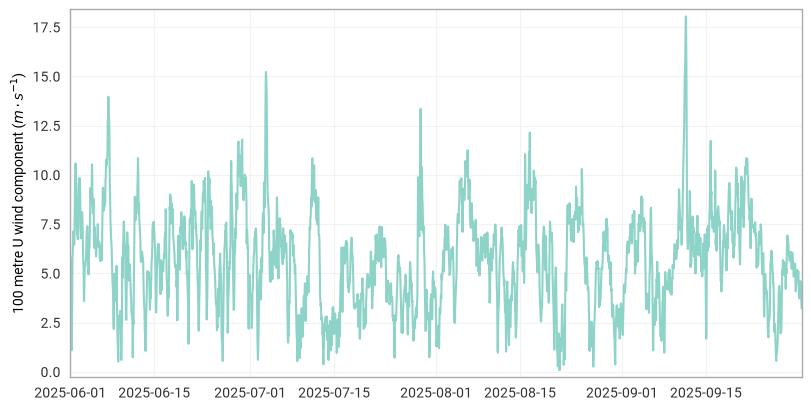

In [35]:
chart = ekp.TimeSeries()

# Plot our hourly data as a line
chart.line(s)
chart.ylabel()

chart.show()


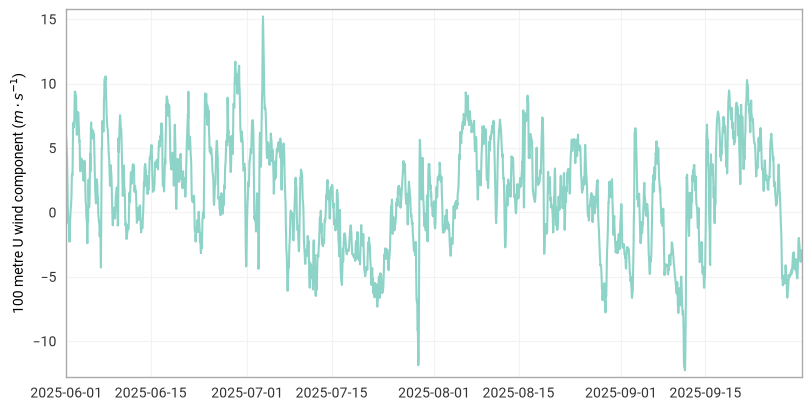

In [38]:
chart = ekp.TimeSeries()

chart.line(data)
chart.ylabel()

chart.show()

---

## Exercises

Moved to a standalone, self-contained notebook: [`exercises.ipynb`](./exercises.ipynb).

It carries its own setup, so it can be run without this notebook, and each task links the specific docs page that answers it.